# k-NN V5

For this experiment, I wanted to see if weighted voting would improve the accuracy. I kept the same k values and Euclidean distance, and compared majority voting with weighted voting.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

image_k = 1
sentiment_k = 3
voting_methods = ["majority", "weighted"]


I started by comparing both voting methods on the image dataset.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
image_X_train = X_train[:1000]
image_y_train = y_train[:1000]
image_X_val = X_val[:200]
image_y_val = y_val[:200]

result_dir = project_root / "results" / "image"
v4_validation = pd.read_csv(result_dir / "knn_v4_validation.csv")
v4_summary = pd.read_csv(result_dir / "knn_v4_summary.csv")
assert v4_validation["validation_index"].tolist() == list(range(200))
assert v4_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_validation_predictions = {}
image_best_accuracy = -1
print("Image: k=" + str(image_k) + ", 1000 training samples, 200 validation samples")
for voting_method in voting_methods:
    clf = KNNClassifier(k=image_k, distance_fn=euclidean_distance, voting_method=voting_method)
    clf.fit(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_validation_predictions[voting_method] = y_pred
    image_rows.append({
        "dataset": "image",
        "version": "V5",
        "k": image_k,
        "distance_metric": "euclidean",
        "voting_method": voting_method,
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(image_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"{voting_method:8s}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Majority comes first, so it wins an accuracy tie.
    if accuracy > image_best_accuracy:
        image_best_voting = voting_method
        image_best_accuracy = accuracy
    if voting_method == "majority":
        assert accuracy == 0.215
        assert accuracy == v4_summary.loc[v4_summary["normalized"] == False, "validation_accuracy"].iloc[0]
        assert y_pred == v4_validation["predicted_label"].tolist()

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v5_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_voting],
}).to_csv(result_dir / "knn_v5_validation.csv", index=False)
print(f"Selected: {image_best_voting}, accuracy={image_best_accuracy:.2%}")
assert image_validation_predictions["majority"] == image_validation_predictions["weighted"]
print("Both voting methods produced identical image predictions because k=1.")


Image: k=1, 1000 training samples, 200 validation samples
majority  accuracy=21.50%  prediction time=0.483701 s
weighted  accuracy=21.50%  prediction time=0.463546 s
Selected: majority, accuracy=21.50%
Both voting methods produced identical image predictions because k=1.


Then I repeated the same test with the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
sentiment_X_train = X_train[:1000]
sentiment_y_train = y_train[:1000]
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]

result_dir = project_root / "results" / "sentiment"
v4_validation = pd.read_csv(result_dir / "knn_v4_validation.csv")
v4_summary = pd.read_csv(result_dir / "knn_v4_summary.csv")
assert v4_validation["validation_index"].tolist() == list(range(200))
assert v4_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_validation_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: k=" + str(sentiment_k) + ", 1000 training samples, 200 validation samples")
for voting_method in voting_methods:
    clf = KNNClassifier(k=sentiment_k, distance_fn=euclidean_distance, voting_method=voting_method)
    clf.fit(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_validation_predictions[voting_method] = y_pred
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V5",
        "k": sentiment_k,
        "distance_metric": "euclidean",
        "voting_method": voting_method,
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(sentiment_X_val),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"{voting_method:8s}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # Majority comes first, so it wins an accuracy tie.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_voting = voting_method
        sentiment_best_accuracy = accuracy
    if voting_method == "majority":
        assert accuracy == 0.575
        assert accuracy == v4_summary.loc[v4_summary["normalized"] == False, "validation_accuracy"].iloc[0]
        assert y_pred == v4_validation["predicted_label"].tolist()

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v5_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_voting],
}).to_csv(result_dir / "knn_v5_validation.csv", index=False)
print(f"Selected: {sentiment_best_voting}, accuracy={sentiment_best_accuracy:.2%}")


Sentiment: k=3, 1000 training samples, 200 validation samples
majority  accuracy=57.50%  prediction time=0.866953 s
weighted  accuracy=57.50%  prediction time=0.423984 s
Selected: majority, accuracy=57.50%


I plotted the accuracies to compare both voting methods.

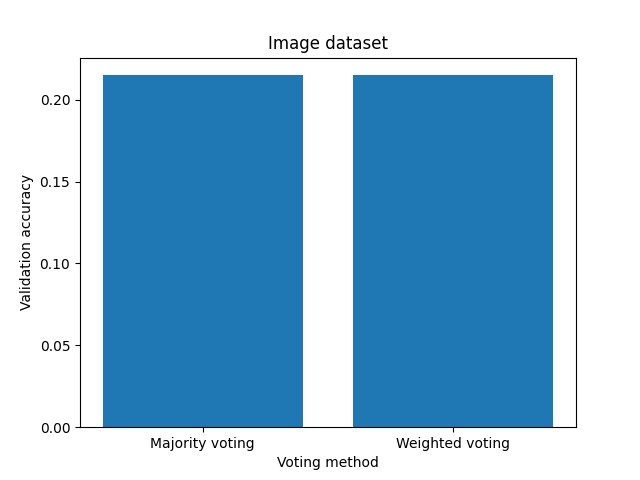

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.bar(["Majority voting", "Weighted voting"], image_summary["validation_accuracy"])
plt.xlabel("Voting method")
plt.ylabel("Validation accuracy")
plt.title("Image dataset")
plt.savefig(knn_result_dir / "knn_v5_image_accuracy.png")
plt.show()


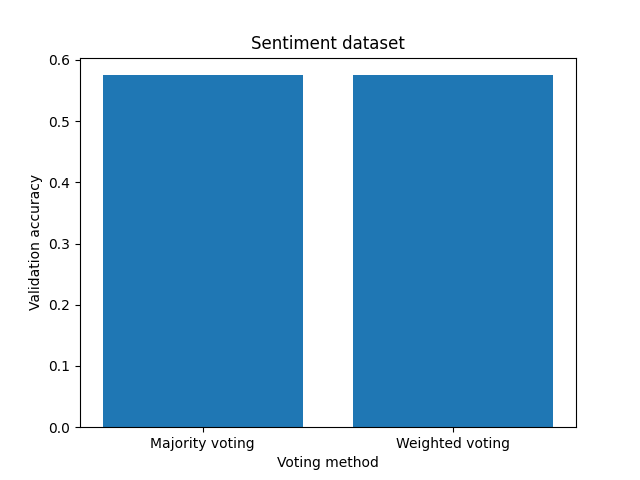

In [5]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.bar(["Majority voting", "Weighted voting"], sentiment_summary["validation_accuracy"])
plt.xlabel("Voting method")
plt.ylabel("Validation accuracy")
plt.title("Sentiment dataset")
plt.savefig(knn_result_dir / "knn_v5_sentiment_accuracy.png")
plt.show()


Finally, I compared the results to see which voting method worked best.

In [6]:
print(f"Image:     k={image_k}, {image_best_voting} voting, accuracy={image_best_accuracy:.2%}")
print(f"Sentiment: k={sentiment_k}, {sentiment_best_voting} voting, accuracy={sentiment_best_accuracy:.2%}")


Image:     k=1, majority voting, accuracy=21.50%
Sentiment: k=3, majority voting, accuracy=57.50%


I used the best voting method for each dataset to predict the test labels.

In [7]:
image_clf = KNNClassifier(
    k=image_k, distance_fn=euclidean_distance, voting_method=image_best_voting
)
image_clf.fit(image_X_train, image_y_train)
start = perf_counter()
image_test_predictions = image_clf.predict(image_X_test)
print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Image: predicted 5000 test labels in 15.33 s


In [8]:
sentiment_clf = KNNClassifier(
    k=sentiment_k, distance_fn=euclidean_distance, voting_method=sentiment_best_voting
)
sentiment_clf.fit(sentiment_X_train, sentiment_y_train)
start = perf_counter()
sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Sentiment: predicted 5000 test labels in 22.25 s


In [9]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v5_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)

v2_submission = pd.read_csv(submission_dir / "submission_v2_knn.csv")
assert saved_submission["id"].tolist() == v2_submission["id"].tolist()
changed_predictions = int((saved_submission["label"] != v2_submission["label"]).sum())
print(f"Identical predictions to V2: {changed_predictions == 0}")
print(f"Changed predictions compared with V2: {changed_predictions}")
if image_best_voting == "majority" and sentiment_best_voting == "majority":
    pd.testing.assert_frame_equal(saved_submission, v2_submission, check_dtype=False)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v5_knn.csv
Identical predictions to V2: True
Changed predictions compared with V2: 0


In [10]:
tracker_path = knn_result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v5_row = {
    "version": "V5",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": submission_path.name,
    "notes": f"Compared majority and weighted voting; image: {image_best_voting}; sentiment: {sentiment_best_voting}.",
}
matching = tracker["version"] == "V5"
if matching.any():
    # Preserve any recorded Kaggle score and status on reruns.
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "submission_filename", "notes"):
        tracker.loc[matching, column] = v5_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v5_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle   submission_filename                                                                                                notes
     V1                      0.21                         0.575                                   False                                                                                k=3 and 1,000 training samples per dataset.
     V2                     0.215                         0.575               0.329                True submission_v2_knn.csv                                             Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
     V3                     0.215                         0.575                                   False submission_v3_knn.csv      Compared Euclidean, Manhattan, Minkowski p=3; best image: Euclidean; best sentiment: Euclidean.
     V4                     0.215                         0.575                             